In [3]:
# ------------------------------------------------------------
# One-way sensitivity analysis on incremental net monetary benefit (INMB)
#
# Why INMB and not the ICER? Apixaban is dominant, so the ICER is
# negative and meaningless. INMB is always interpretable:
# positive = adopt, negative = don't.
# ------------------------------------------------------------
import numpy as np
import pandas as pd
from markov_model import load_inputs, run_both

p, S = load_inputs()
inputs = pd.read_csv("../outputs/inputs.csv", index_col="name")
WTP = S["wtp"]

def inmb(params, settings):
    a, w = run_both(params, settings)
    return (a["qaly"] - w["qaly"]) * WTP - (a["cost"] - w["cost"])

base_inmb = inmb(p, S)
print(f"Reference-case INMB: ${base_inmb:,.0f}")

rows = []
for name, row in inputs.iterrows():           # all 50 parameters
    results = []
    for value in (row["low"], row["high"]):
        q = dict(p)                            # fresh copy each time
        q[name] = value                        # change ONE input only
        results.append(inmb(q, S))
    rows.append({"parameter": row["label"],
                 "low value": row["low"], "high value": row["high"],
                 "INMB at low": results[0], "INMB at high": results[1],
                 "swing": abs(results[1] - results[0])})

# Sort by swing: the biggest drivers go to the top of the tornado
owsa = pd.DataFrame(rows).sort_values("swing", ascending=False).reset_index(drop=True)
owsa.to_csv("../outputs/owsa.csv", index=False)

pd.set_option("display.float_format", "{:,.0f}".format)
print(owsa.head(10)[["parameter", "INMB at low", "INMB at high"]].to_string())
print(f"\nLowest INMB in any one-way analysis: ${owsa[['INMB at low','INMB at high']].min().min():,.0f}")
print("Parameters that flip the decision (INMB < 0):",
      int(((owsa["INMB at low"] < 0) | (owsa["INMB at high"] < 0)).sum()))

Reference-case INMB: $17,421
                                parameter  INMB at low  INMB at high
0                     Apixaban OR: stroke       23,049        11,204
1               Apixaban 5 mg BID, annual       18,569        10,533
2   Non-vascular death at age 70 (annual)       21,030        14,838
3                        Apixaban OR: ICH       18,893        15,482
4                Apixaban OR: major bleed       18,974        15,686
5        Stroke rate on warfarin (annual)       15,845        18,840
6           ICH rate on warfarin (annual)       15,980        18,825
7             Utility: AF, no prior event       16,041        18,802
8                      Aspirin RR: stroke       16,406        18,873
9  INR monitoring, annual (warfarin only)       16,259        18,584

Lowest INMB in any one-way analysis: $10,533
Parameters that flip the decision (INMB < 0): 0


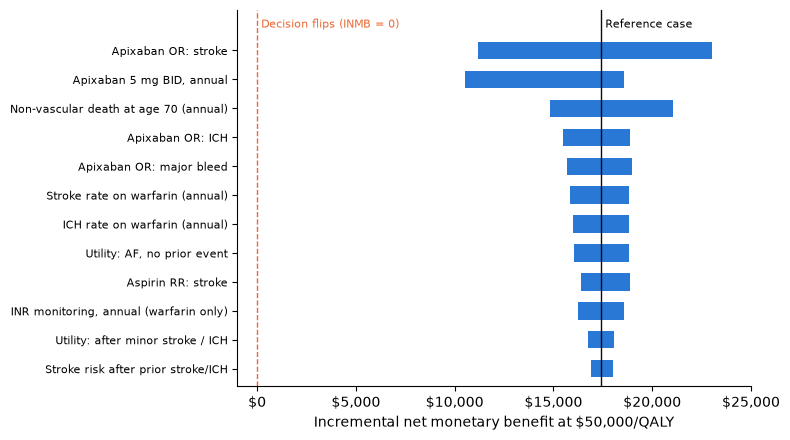

In [4]:
# ------------------------------------------------------------
# Top 12 drivers. Each bar spans INMB at the input's low and high value.
# ------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

top = owsa.head(12).iloc[::-1]       # reverse so the biggest bar is on top
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (lo_val, hi_val) in enumerate(zip(top["INMB at low"], top["INMB at high"])):
    lo, hi = sorted([lo_val, hi_val])
    ax.barh(i, hi - lo, left=lo, color="#2a78d6", height=0.6)

ax.axvline(base_inmb, color="#0b0b0b", lw=1)
ax.axvline(0, color="#eb6834", lw=1, ls="--")
ax.text(base_inmb, len(top) - 0.3, " Reference case", fontsize=8, va="bottom")
ax.text(0, len(top) - 0.3, " Decision flips (INMB = 0)", fontsize=8, va="bottom", color="#eb6834")
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top["parameter"], fontsize=8)
ax.set_xlabel("Incremental net monetary benefit at $50,000/QALY")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlim(-1000, 25000)
ax.set_ylim(-0.6, len(top) + 0.4)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../outputs/fig_tornado.png", dpi=150)
plt.show()

In [5]:
# ------------------------------------------------------------
# Scenarios change STRUCTURE or several inputs at once.
# run_scenario takes optional new parameters and/or settings changes.
# ------------------------------------------------------------
def run_scenario(label, params=None, **setting_changes):
    settings = {**S, **setting_changes}            # copy settings, apply changes
    a, w = run_both(params if params is not None else p, settings)
    d_cost, d_qaly = a["cost"] - w["cost"], a["qaly"] - w["qaly"]
    if d_cost <= 0 and d_qaly >= 0:
        result = "Dominant"
    elif d_cost >= 0 and d_qaly <= 0:
        result = "Dominated"
    else:
        result = f"${d_cost / d_qaly:,.0f}/QALY"
    return {"scenario": label, "incr. cost": d_cost, "incr. QALYs": d_qaly,
            "result": result, "INMB": d_qaly * WTP - d_cost}

# Parameter sets for the scenarios that change inputs
brand = dict(p)
brand["c_apixaban"] = 1.6336 * 2 * 365.25

pessimistic = dict(p)                              # every apixaban benefit at its WORST plausible value
for k in ["or_apx_stroke", "or_apx_mi", "or_apx_ich", "or_apx_mb"]:
    pessimistic[k] = inputs.loc[k, "high"]

no_stroke_benefit = dict(p)                        # stress test: zero stroke benefit
no_stroke_benefit["or_apx_stroke"] = 1.0

no_inr = dict(p)                                   # e.g. patient self-testing at home
no_inr["c_inr"] = 0.0

scenarios = pd.DataFrame([
    run_scenario("Reference case"),
    run_scenario("Brand apixaban price (Eliquis)", brand),
    run_scenario("Discount rate 0%", discount_rate=0.0),
    run_scenario("Discount rate 3%", discount_rate=0.03),
    run_scenario("Time horizon 2 years (trial length)", max_age=72),
    run_scenario("Time horizon 10 years", max_age=80),
    run_scenario("Effect wanes 5%/yr after year 2", wane_start=2, wane_decay=0.05),
    run_scenario("All apixaban ORs at upper 95% CI", pessimistic),
    run_scenario("No stroke benefit (OR stroke = 1)", no_stroke_benefit),
    run_scenario("No INR monitoring cost", no_inr),
    run_scenario("Cohort starts at age 80", start_age=80),
])
scenarios.to_csv("../outputs/scenarios.csv", index=False)

pd.set_option("display.float_format", "{:,.3f}".format)
print(scenarios.to_string(index=False))

                           scenario  incr. cost  incr. QALYs      result       INMB
                     Reference case  -5,607.909        0.236    Dominant 17,421.428
     Brand apixaban price (Eliquis)   1,280.252        0.236 $5,419/QALY 10,533.268
                   Discount rate 0%  -6,194.058        0.281    Dominant 20,221.712
                   Discount rate 3%  -5,104.618        0.201    Dominant 15,136.925
Time horizon 2 years (trial length)    -821.941        0.004    Dominant  1,031.676
              Time horizon 10 years  -4,357.397        0.097    Dominant  9,230.504
    Effect wanes 5%/yr after year 2  -4,912.092        0.207    Dominant 15,256.943
   All apixaban ORs at upper 95% CI  -2,613.642        0.092    Dominant  7,238.022
  No stroke benefit (OR stroke = 1)  -3,051.454        0.125    Dominant  9,305.759
             No INR monitoring cost  -3,282.942        0.236    Dominant 15,096.462
            Cohort starts at age 80  -3,125.202        0.105    Dominant  8,